# Unemployment and inflation — ARDL with makystats

**Series.** US quarterly `unemp` and `infl` (`data/us_macro_quarterly.csv`).

**Order selection (case 3).**

| Criterion | Preferred |
|-----------|-----------|
| **BIC and AIC** | `ARDL(3; 2)` |

Main model: **ARDL(3, 2), case 3**. ARDL(2, 2) is competitive but **not** IC-best.


## 1. Setup


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from makystats import ardl, select_ardl_order

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (11, 4.5)

## 2. Data


In [2]:
md = pd.read_csv("data/us_macro_quarterly.csv")
md.index = pd.PeriodIndex.from_fields(
    year=md["year"].astype(int), quarter=md["quarter"].astype(int), freq="Q"
)
y = md["unemp"].astype(float)
x = md[["infl"]].astype(float)
print(y.index[0], "→", y.index[-1], f"({len(y)} obs.)")


1959Q1 → 2009Q3 (203 obs.)


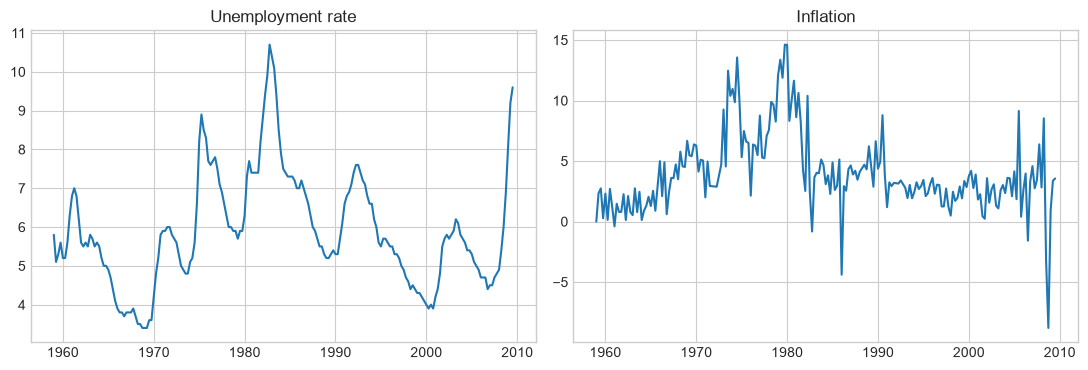

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(y.to_timestamp()); axes[0].set_title("Unemployment rate")
axes[1].plot(x["infl"].to_timestamp()); axes[1].set_title("Inflation")
fig.tight_layout()
plt.show()

## 3. Order selection


In [4]:
table = select_ardl_order(
    y, x=x, maxlag=4, maxorder=3, case=3, ic="bic", verbose=False
)
print(table.head(8))
print("Best (BIC):", table.index[0])

            p        order        aic        bic       hqic        ll  n_obs  \
ARDL(3; 2)  3  {'infl': 2}   4.206234  27.294455  13.549684  4.896883    200   
ARDL(2; 3)  2  {'infl': 3}   4.297452  27.385674  13.640902  4.851274    200   
ARDL(2; 2)  2  {'infl': 2}   9.991030  29.810859  18.010992  1.004485    201   
ARDL(3; 1)  3  {'infl': 1}  10.969278  30.759182  18.977950  0.515361    200   
ARDL(2; 1)  2  {'infl': 1}  15.970512  32.487037  22.653814 -2.985256    201   
ARDL(3; 3)  3  {'infl': 3}   6.192519  32.579058  16.870748  4.903740    200   
ARDL(4; 2)  4  {'infl': 2}   6.984289  33.330728  17.647374  4.507855    199   
ARDL(3; 0)  3  {'infl': 0}  17.333796  33.825383  24.007689 -3.666898    200   

            case  q_infl  q  
ARDL(3; 2)     3       2  2  
ARDL(2; 3)     3       3  3  
ARDL(2; 2)     3       2  2  
ARDL(3; 1)     3       1  1  
ARDL(2; 1)     3       1  1  
ARDL(3; 3)     3       3  3  
ARDL(4; 2)     3       2  2  
ARDL(3; 0)     3       0  0  
Best (BIC

### Reading the table

- **ARDL(3; 2)** leads AIC and BIC.
- ARDL(2; 2) is nearby; prefer (3, 2) when reporting a single preferred model.


## 4. Main model: ARDL(3, 2), case 3


In [5]:
res = ardl(y, x=x, lags=3, order=2, case=3).fit(verbose=False)
print(res.summary())

                              ARDL Model Results                              
Dep. Variable: unemp                                     No. Observations: 200
Model:         ARDL(3, 2)                              Log Likelihood:   4.897
Method:        OLS (conditional)                    S.D. of innov.:   0.236711
Case (PSS):    3 (Constant)                            AIC:              4.206
Date:          Tue, 27 Oct 2026                       BIC:              27.294
Time:          17:31:08                               HQIC:             13.550
               coef    std err          t      P>|t|     [0.025     0.975]
const        0.1959     0.0765     2.5601     0.0112     0.0450     0.3469
unemp.L1     1.6481     0.0697    23.6296     0.0000     1.5105     1.7857
unemp.L2    -0.7127     0.1260    -5.6546     0.0000    -0.9613    -0.4641
unemp.L3     0.0227     0.0705     0.3219     0.7479    -0.1163     0.1617
infl.L0     -0.0179     0.0073    -2.4690     0.0144    -0.0322    -0.00

### Interpretation

- Bounds typically reject “no levels relationship” at 5% (Pesaran); still a **reduced form**, not a structural Phillips curve.
- Use **CUSUM** — unemployment–inflation links are historically unstable.


## 5. UECM (Conditional EC) and bounds test

`summary_uecm()` reports the **conditional error-correction** form (levels of \(y\) and \(x\) lagged, short-run differences) and the **long-run multipliers** \(\theta\).

`summary_bounds()` is the Pesaran / Narayan **F-bounds** test for a levels relationship.


In [6]:
print(res.summary_uecm())
print(res.summary_bounds())

                              UECM Model Results                              
Dep. Variable: D.unemp                                   No. Observations: 200
Model:         UECM(3, …)                              Log Likelihood:   4.897
Method:        OLS (reparam. ARDL)                     AIC:              4.206
Case (PSS):    3 (Constant)                           BIC:              27.294
                 coef    std err          t      P>|t|     [0.025     0.975]
const          0.1959     0.0765     2.5601     0.0112     0.0450     0.3469
unemp.L1      -0.0419     0.0124    -3.3715     0.0009    -0.0664    -0.0174
D.unemp.L1     0.6900     0.0680    10.1413     0.0000     0.5558     0.8242
D.unemp.L2    -0.0227     0.0705    -0.3219     0.7479    -0.1617     0.1163
infl.L1        0.0145     0.0061     2.3981     0.0174     0.0026     0.0264
D.infl.L0     -0.0179     0.0073    -2.4690     0.0144    -0.0322    -0.0036
D.infl.L1     -0.0217     0.0074    -2.9401     0.0037    -0.0363 

## 6. Diagnostics and stability


                            ECM (Error Correction)                            
                 coef    std err          t      P>|t|
COINTEQ       -0.0419     0.0105    -3.9827     0.0001
D.infl.L0     -0.0179     0.0070    -2.5554     0.0114
D.infl.L1     -0.0217     0.0072    -3.0132     0.0029
D.unemp.L1     0.6900     0.0679    10.1680     0.0000
D.unemp.L2    -0.0227     0.0698    -0.3251     0.7455
const          0.1959     0.0501     3.9100     0.0001

Half-life (approx.): 16.189
α=-0.0419 (p=9.631e-05) : retour vers l'équilibre (α<0)
None


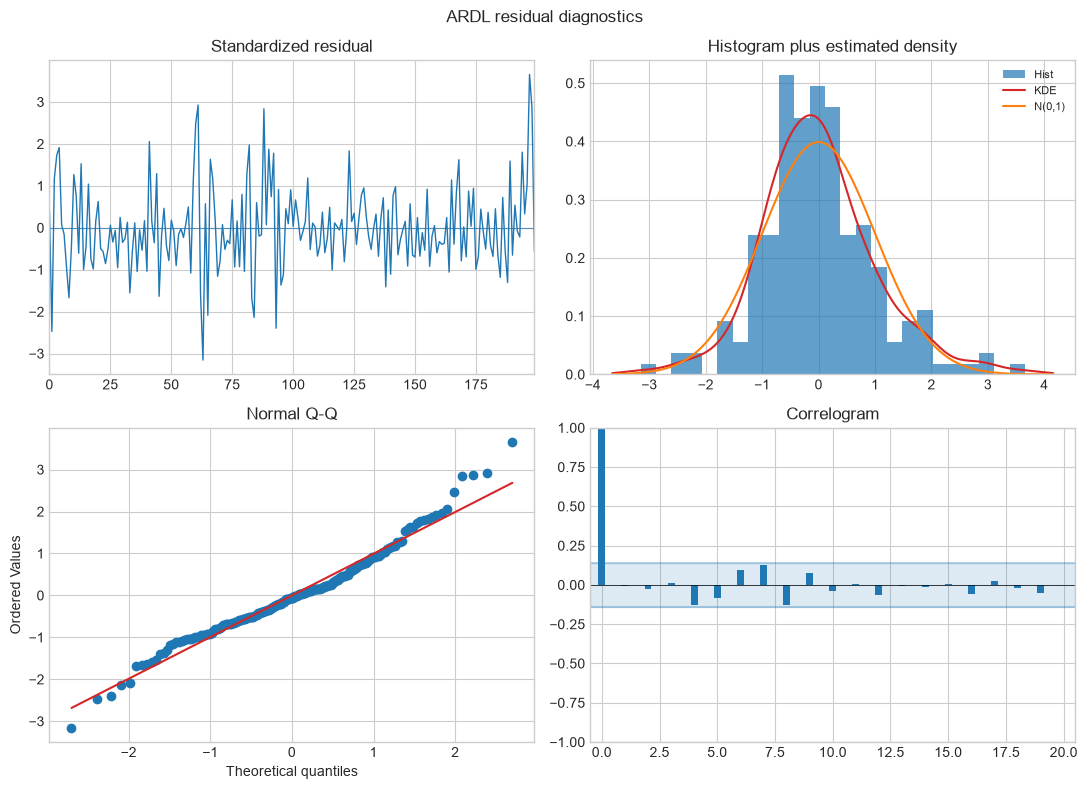

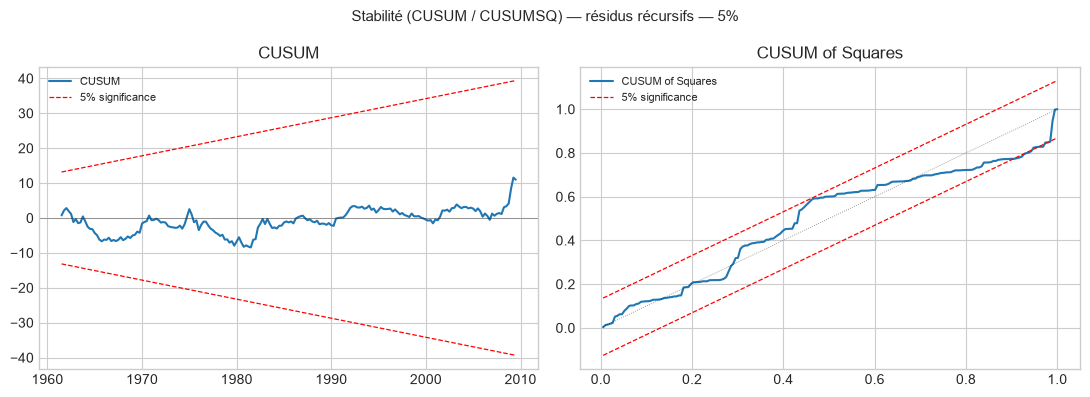

In [7]:
print(res.summary_ecm())
fig = res.plot_diagnostics()
plt.show()
if hasattr(res, "plot_cusum"):
    res.plot_cusum()
    plt.show()

## Takeaways

1. IC → **ARDL(3, 2)** on this sample (not (2, 2)).
2. Report bounds **and** stability diagnostics for macro pairs like this.
3. Long-run coefficients are descriptive without a fuller identification story.
